# Figure 11

**Collapse of the permeability onto the current gas fraction**

(a) $\mathrm{tr}(\tilde{k})/(2k_m)$ versus the current gas fraction $\tilde{\phi}_g$, with the permeability κ0(φ) of the undeformed unit cells and the Hashin–Shtrikman bound $h(\phi)$; (b) relative deviation from κ0; (c) anisotropy $a_D$ of the spatial permeability.

This notebook only post-processes the results of other notebooks, which must be run first:

1. `Fig9.ipynb` and `Fig10.ipynb` (default mesh, $l = 0.03$);
2. `Fig11-kappa0.ipynb` (κ0 of the undeformed unit cells);
3. `Fig11-refined.ipynb` (symmetric loadings on the refined mesh).

It also writes the tables behind Fig. 11 and prints the numbers quoted in the text.

---

**Authors**

Haotian XIAO
Martin GENET

École Polytechnique, Palaiseau, France

## Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

# Plot_Microporoflow is not imported here: it changes the global matplotlib font sizes when it is
# imported, and Fig. 11 is drawn with the default matplotlib settings.
import Post_Microporoflow as pm
import Quiet_Microporoflow as qm

## Output directory

In [2]:
# All results, tables and figures of this notebook are written to the subdirectory Fig11/
# of the notebook directory (demos/).
RESULTS_DIR = Path("Fig11").resolve()
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("RESULTS_DIR =", qm.display_path(RESULTS_DIR))

RESULTS_DIR = Fig11


## Parameters

In [3]:
do_plot          = 1  # Fig. 11
do_tables        = 1  # tables behind Fig. 11 (csv, md)
do_paper_numbers = 1  # numbers quoted in the text

r0_list = (0.07, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.41, 0.45)

# Results of the other notebooks
FIG9_DIR  = Path("Fig9").resolve() / "Figure9_gas_loading"
FIG10_DIR = Path("Fig10").resolve() / "Figure10_loading_comparison"
LIN_DEF   = Path("Fig11-kappa0").resolve() / "linear_hex_l0.03"
LIN_REF   = Path("Fig11-kappa0").resolve() / "linear_hex_l0.015_local"
REF_DIR   = Path("Fig11-refined").resolve() / "l0.015_local"

figure_path = RESULTS_DIR / "Figure11_collapse.pdf"

## Input check

In [4]:
pm.require_files(pm.fig11_input_files(FIG9_DIR, FIG10_DIR, LIN_DEF, LIN_REF, REF_DIR, r0_list))

All 345 input files found (Fig10.ipynb, Fig9.ipynb, Fig11-kappa0.ipynb, Fig11-refined.ipynb).


## Computing κ0(φ) and the permeability along the loading paths

In [5]:
fig11 = pm.fig11_data(FIG9_DIR, FIG10_DIR, LIN_DEF, LIN_REF, REF_DIR, r0_list)

Isotropy of the refined symmetric loadings: max |K_yy/K_xx - 1| = 2.79e-05; undeformed refined RVEs: r0 = 0.07: +2.17e-07, r0 = 0.3: +6.92e-06


## Plot Figure 11

Figure saved in: Fig11/Figure11_collapse.pdf


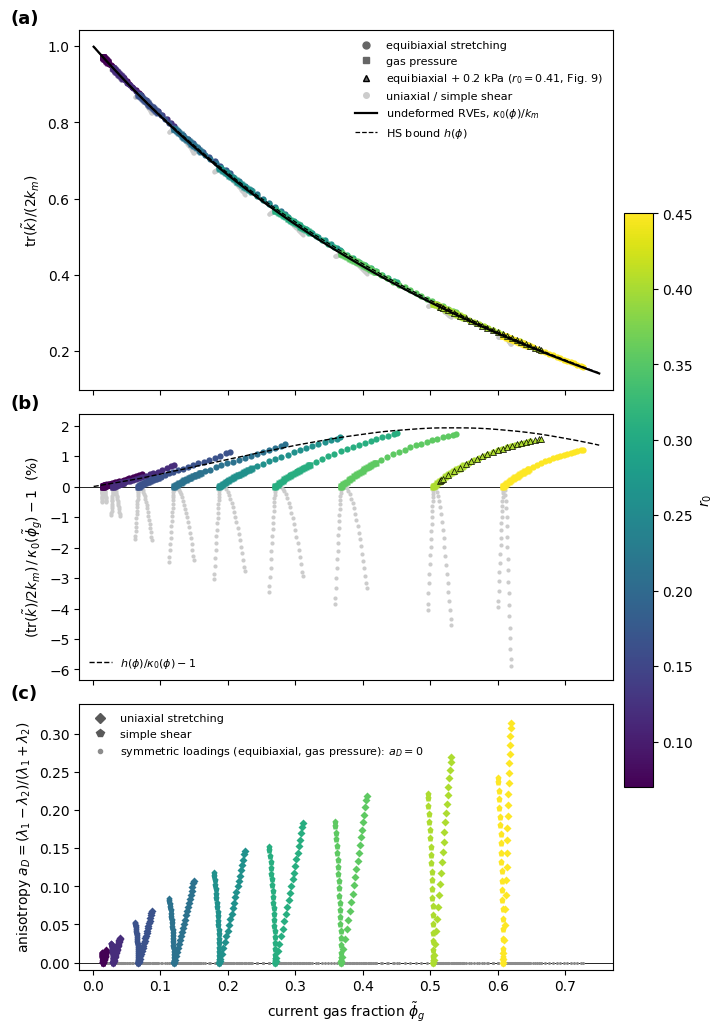

In [6]:
if do_plot:
    fig = pm.plot_figure11(fig11, figure_path)
    plt.show()

## Tables

In [7]:
if do_tables:
    pm.write_fig11_tables(fig11, RESULTS_DIR, FIG10_DIR)

Tables written in Fig11 : kappa0_table.csv, table2_refined.csv, deviation_range_default.csv, anisotropy.csv, path_independence.csv, l1_decomposition_h.csv, fig11_report.md


## Paper numbers

In [8]:
# Each line: [location in the paper] quantity = value [data used]
if do_paper_numbers:
    paper_numbers = pm.paper_numbers(fig11, FIG10_DIR)
    pm.print_paper_numbers(paper_numbers)

[Abstract] kinematic update error, equibiaxial r0 = 0.07 (Phi_g0 = 0.0147)
    = +11.46%    [default mesh l = 0.03 (Fig. 10)]
[Introduction] kinematic update error, equibiaxial, max over r0 (r0 = 0.41)
    = +51.48%    [default mesh l = 0.03 (Fig. 10)]
[Abstract; Sec. 3.5.2] gas-fraction update vs RVE, |C_h/C_RVE - 1|, volumic, max over r0 (r0 = 0.41)
    = 1.62%    [refined mesh (Fig. 11(b))]
[Abstract; Sec. 3.5.2] gas-fraction update vs RVE, |C_h/C_RVE - 1|, gas_pressure, max over r0 (r0 = 0.41)
    = 0.68%    [refined mesh (Fig. 11(b))]
[Sec. 3.5.2] equibiaxial r0 = 0.07: J final, Phi_g0 -> phi_g final
    = J = 1.6900, 0.0147 -> 0.0722    [refined mesh (Fig. 11(b))]
[Sec. 3.5.2] path independence: gas pressure vs equibiaxial at equal phi_g, max |rel| (r0 = 0.35)
    = -0.0098%    [default mesh (Fig. 11(a))]
[Sec. 3.5.2] path independence: Fig. 9 (+0.2 kPa) vs equibiaxial r0 = 0.41, max |rel| over 19 frames
    = 0.0036%    [default mesh (Fig. 11(a))]
[Sec. 3.5.2] max deviation abov